# The Bread Basket — EDA and Business Decisions

**Project:** Bakery Preparation Planning Dashboard  
**Decision-maker:** Bakery Store Manager  
**Recurring decision:** When should we prepare, and which baked goods should we prioritize?  

This notebook deliberately separates **descriptive evidence** from **operational assumptions**. The Kaggle file is a frozen 2016–2017 snapshot. There are no inventory levels, employee rosters, prices, or verified wasted units in this file.

**Dataset:** https://www.kaggle.com/datasets/mittalvasu95/the-bread-basket

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "bakery_analysis.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from bakery_analysis import (
    DATA_FILE, FOCUS_ITEMS, TIME_WINDOWS, load_transactions,
    filter_day_type, order_rows, item_order_rows, daily_transactions,
    hourly_transaction_rates, bakery_item_window_rates, dashboard_metrics
)
plt.rcParams.update({"figure.figsize": (8.5, 3.5), "axes.spines.top": False, "axes.spines.right": False})
print("Dataset:", DATA_FILE.name)

Dataset: bread_basket.csv


## 1. Data structure and checks

**Unit of observation:** one row is one item entry for a transaction; *not* necessarily one order and *not* an observed sales quantity. Check parsing, data types and missing values before interpreting any KPI.

In [2]:
raw = pd.read_csv(DATA_FILE)
print("Rows / columns:", raw.shape)
print("Column types:\n", raw.dtypes.to_string())
print("Null cells by column:\n", raw.isna().sum().to_string())
print("Fully duplicated rows:", raw.duplicated().sum())
display(raw.head(8))

Rows / columns: (20507, 5)
Column types:
 Transaction         int64
Item               object
date_time          object
period_day         object
weekday_weekend    object
Null cells by column:
 Transaction        0
Item               0
date_time          0
period_day         0
weekday_weekend    0
Fully duplicated rows: 1620


,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,30-10-2016 09:58,morning,weekend
1,2,Scandinavian,30-10-2016 10:05,morning,weekend
2,2,Scandinavian,30-10-2016 10:05,morning,weekend
3,3,Hot chocolate,30-10-2016 10:07,morning,weekend
4,3,Jam,30-10-2016 10:07,morning,weekend
5,3,Cookies,30-10-2016 10:07,morning,weekend
6,4,Muffin,30-10-2016 10:08,morning,weekend
7,5,Coffee,30-10-2016 10:13,morning,weekend


### A duplicate-row warning

There are multiple rows with identical `(Transaction, Item, date_time)`. Such rows may reflect more than one item purchased in an order, rather than accidental import duplicates. We **retain the raw rows** but use:

- Unique `Transaction` ID → number of distinct orders.
- Unique `(Transaction, Item)` pair → number of orders containing a named product.

There is no separate quantity field, so do **not** label either of these as precise *units sold*.

In [3]:
data = load_transactions(DATA_FILE)
orders = order_rows(data)
order_items = item_order_rows(data)
summary = pd.Series({
    "Raw item rows":len(data),
    "Distinct transactions":len(orders),
    "Unique item labels":data.Item.nunique(),
    "Recorded dates":data.date.nunique(),
    "Repeated full raw rows":raw.duplicated().sum(),
    "Distinct order-item pairs":len(order_items),
})
display(summary.to_frame("Value"))
print("Date range:", data.timestamp.min(), "to", data.timestamp.max())
print("Inconsistent transaction timestamps:", int((data.groupby('Transaction').timestamp.nunique()>1).sum()))

,Value
Raw item rows,20507
Distinct transactions,9465
Unique item labels,94
Recorded dates,159
Repeated full raw rows,1620
Distinct order-item pairs,18887


Date range: 2016-10-30 09:58:00 to 2017-04-09 15:04:00
Inconsistent transaction timestamps: 0


## 2. Date coverage and outliers

**Do not impute days without records as zero-demand opening days.** The data does not provide a store-opening calendar. Some observed dates also have atypical hours or a very small number of transactions.

In [4]:
dates = pd.date_range(data.date.min(), data.date.max(), freq="D")
missing_dates = dates.difference(pd.DatetimeIndex(data.date.drop_duplicates()))
print("Dates in calendar span without transaction records:", [d.strftime('%Y-%m-%d') for d in missing_dates])
by_day = daily_transactions(data)
print("Lowest daily transaction counts:")
display(by_day.nsmallest(7, "transactions"))
print("Raw orders outside main 08:00–17:59 chart window:", len(orders.loc[~orders.hour.between(8,17)]))

Dates in calendar span without transaction records: ['2016-12-25', '2016-12-26', '2017-01-02']
Lowest daily transaction counts:


,date,day_type,transactions
61,2017-01-01,Weekend,1
56,2016-12-27,Weekday,23
158,2017-04-09,Weekend,32
77,2017-01-18,Weekday,34
126,2017-03-08,Weekday,34
105,2017-02-15,Weekday,35
117,2017-02-27,Weekday,36


Raw orders outside main 08:00–17:59 chart window: 130


## 3. Compare day types fairly

Since there are different numbers of observed weekdays and weekend days, compare **average transactions per recorded date**, not total transaction counts.

,recorded_days,transactions,avg_per_recorded_day
day_type,,,
Weekday,113,6145,54.38
Weekend,46,3320,72.17


Weekend mean per recorded date is 32.7% above weekday mean (descriptive only).


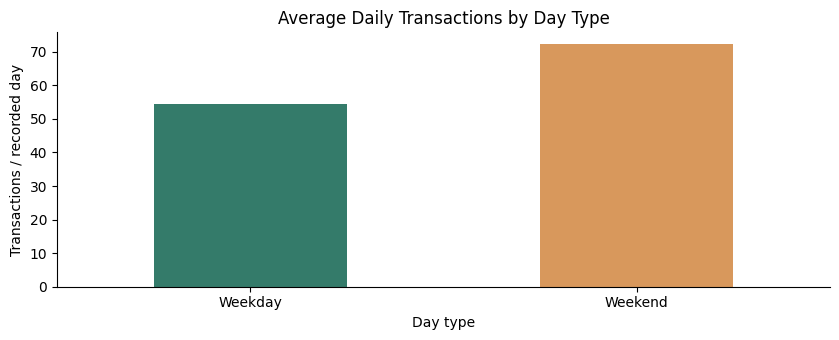

In [5]:
day_comparison = (
    by_day.groupby('day_type')
    .agg(recorded_days=('date','nunique'), transactions=('transactions','sum'),
         avg_per_recorded_day=('transactions','mean'))
    .reindex(['Weekday', 'Weekend'])
)
display(day_comparison.round(2))
lift = (day_comparison.loc['Weekend','avg_per_recorded_day'] /
        day_comparison.loc['Weekday','avg_per_recorded_day'] - 1) * 100
print(f"Weekend mean per recorded date is {lift:.1f}% above weekday mean (descriptive only).")
ax = day_comparison['avg_per_recorded_day'].plot(kind='bar', rot=0, color=['#347B6A','#D8985C'])
ax.set(title='Average Daily Transactions by Day Type', xlabel='Day type', ylabel='Transactions / recorded day')
plt.tight_layout(); plt.show()

### Robustness check: unusual January 1 record

The historical snapshot includes one transaction at 01:21 on January 1, 2017. It is not obviously a normal trading day; show how the weekend average changes if we set this single atypical date aside. The dashboard itself retains the date and discloses the issue.

In [6]:
suspicious = pd.Timestamp('2017-01-01')
weekend_orders = order_rows(filter_day_type(data, "Weekend"))
weekend_without = weekend_orders[weekend_orders.date != suspicious]
print('Including observed Jan 1: ', round(len(weekend_orders)/weekend_orders.date.nunique(),2))
print('Excluding unusual Jan 1: ', round(len(weekend_without)/weekend_without.date.nunique(),2))

Including observed Jan 1:  72.17
Excluding unusual Jan 1:  73.76


## 4. Hourly transaction demand

Our decision is *when to prepare*. Plot average hourly transaction counts for observed weekdays and weekends separately. The chart covers 08:00–17:59, while rare out-of-window records still count in the overall daily KPI.

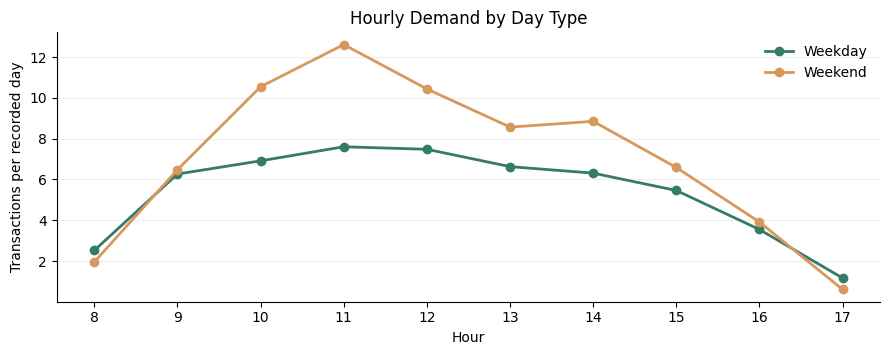

Main-window peak hour: 11


In [7]:
fig, ax = plt.subplots(figsize=(9.0,3.65))
for typ,color in [('Weekday','#347B6A'),('Weekend','#D8985C')]:
    hourly = hourly_transaction_rates(filter_day_type(data, typ))
    ax.plot(hourly.index, hourly.values, marker='o', label=typ, color=color, linewidth=2)
ax.set(title='Hourly Demand by Day Type', xlabel='Hour', ylabel='Transactions per recorded day')
ax.set_xticks(list(range(8,18))); ax.legend(frameon=False); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.show()
print('Main-window peak hour:', dashboard_metrics(data)['peak_hour'])

## 5. Product priorities by time window

Our decision is *what to prepare*. This chart shows daily incidence of **8 explicit baked-goods labels**, not quantities sold. Morning contains 08:00–11:59 (4 hours), afternoon contains 12:00–16:59 (5 hours); those windows have different lengths.

preparation_window,Morning (08–11),Afternoon (12–16)
Item,,
Bread,9.35,9.79
Cake,1.63,4.38
Pastry,3.58,1.47
Medialuna,2.36,1.19
Cookies,1.23,1.89
Brownie,0.77,1.57
Muffin,0.92,1.30
Scone,0.69,1.35


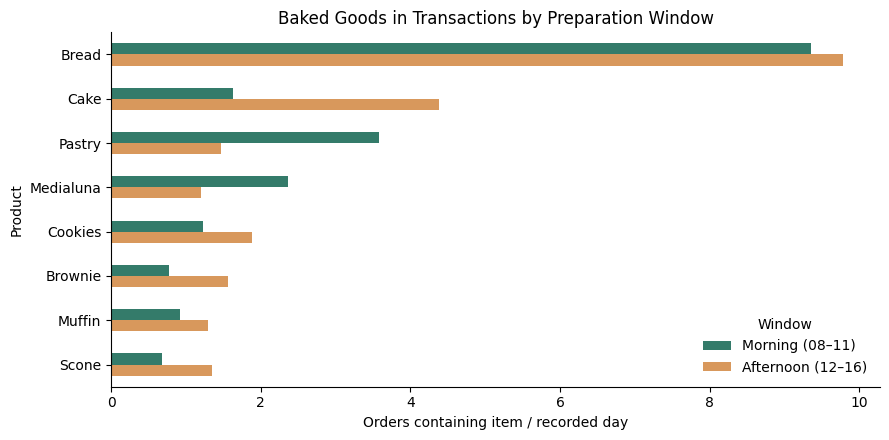

In [8]:
product = bakery_item_window_rates(data, top_n=8)
display(product.round(2))
ax = product.plot.barh(figsize=(9.0, 4.5), color=['#347B6A','#D8985C'])
ax.invert_yaxis()
ax.set(title='Baked Goods in Transactions by Preparation Window',
       xlabel='Orders containing item / recorded day',ylabel='Product')
ax.legend(title='Window',frameon=False)
plt.tight_layout(); plt.show()

### Validate the morning/afternoon bakery patterns

Counts below are the number of **distinct transactions containing the item** in the window. They are not item units and cannot by themselves determine how many to bake.

In [9]:
product_pairs = item_order_rows(data)
for item in ['Pastry','Cake','Bread']:
    p = product_pairs[product_pairs.Item == item]
    morning = (p.preparation_window == TIME_WINDOWS[0]).sum()
    afternoon = (p.preparation_window == TIME_WINDOWS[1]).sum()
    print(f'{item:8} | morning orders: {morning:4} | afternoon orders: {afternoon:4}')

Pastry   | morning orders:  570 | afternoon orders:  233
Cake     | morning orders:  259 | afternoon orders:  696
Bread    | morning orders: 1487 | afternoon orders: 1556


## 6. Why not use raw monthly totals as a headline chart?

The first and last months are partial months. Raw total sales by month reflect both demand and the number of days covered. This is an example of something useful to check during EDA but **not** worth placing above the manager's operational chart.

In [10]:
monthly = (
    by_day.assign(month=by_day.date.dt.to_period('M').astype(str))
    .groupby('month')
    .agg(transactions=('transactions','sum'),recorded_days=('date','nunique'),
         avg_daily=('transactions','mean'))
)
display(monthly.round(2))

,transactions,recorded_days,avg_daily
month,,,
2016-10,175,2,87.50
2016-11,2140,30,71.33
2016-12,1672,29,57.66
2017-01,1575,30,52.50
2017-02,1630,28,58.21
2017-03,1764,31,56.90
2017-04,509,9,56.56


## 7. From EDA to decisions

**What goes on the dashboard?**

1. KPI: Average daily transactions (answers how busy a comparable recorded day is).
2. KPI: Busiest daytime hour (answers **when** to prepare).
3. KPI: Most requested focus bakery item (answers **what** to prepare).
4. Chart: Average hourly transactions (explains the peak hour).
5. Chart: Baked-goods orders in morning vs afternoon (explains product priorities).
6. Filter: Weekday vs weekend (changes the preparation context).

**What do we deliberately leave out?** Full 94-item sales rankings and market-basket network visualizations. Both are interesting but distracting for this manager's immediate question.

**Data limitations:** No prices, inventory, production, waste, staffing records or validated store opening schedule. No claim of exact bake quantities or measured savings.

**Proposed operations:** nightly POS refresh; manager review in the morning and for the coming week; monitor 11:00–11:59 order demand and investigate a sustained change above a provisional 20% threshold. The historical CSV does not itself refresh.

**Next step:** `uv run streamlit run app.py`, verify the `Weekday / Weekend` filter changes all KPIs and charts, then finish the individual README and deployment.